
# Taller 1 — Teoría de Aprendizaje de Máquina (2026-2)

**Tema:** Clasificación supervisada, vecinos cercanos y evaluación de modelos
**Profesor:** Diego Armando Pérez Rosero
**Autor:** Cristian David Dorado Gómez

Cuaderno reproducible de la solución. Contiene los procedimientos manuales
(redactados en celdas Markdown con su justificación), el código en Python con
resultados numéricos, figuras y discusión.

**Semillas fijas:** `np.random.seed(42)`, `random_state=42` en `make_moons` y en
`train_test_split`.

**Contenido**

1. Clasificación lineal y algoritmo del perceptrón (1.1, 1.2, 1.3).
2. Clasificación por los $k$ vecinos más cercanos (2.1, 2.2, 2.3).
3. Evaluación de un clasificador binario (3.1, 3.2, 3.3).



## Cómo ejecutar este cuaderno

**Google Colab.** Subir el archivo a Drive (o *Archivo > Subir cuaderno*) y
elegir *Entorno de ejecución > Ejecutar todo*. Colab ya incluye `numpy`,
`scikit-learn` y `matplotlib`, así que no hace falta instalar nada: la primera
celda de código comprueba las dependencias y, si faltara alguna, la instala con
`pip`. El cuaderno es autocontenido: no lee archivos externos, genera sus propios
datos con semilla fija y escribe las figuras en `figuras/` y el resumen numérico
en `resultados.json` dentro del directorio de trabajo (en Colab, `/content`).

**Local.** Tener Python 3.10 o superior con `numpy`, `scikit-learn` y
`matplotlib`; ejecutar todas las celdas en orden. Versiones con las que se
desarrolló: Python 3.14, `numpy 2.5.4`, `scikit-learn 1.9.1`,
`matplotlib 3.11.2`.

**Tiempo de ejecución:** menos de un minuto en un entorno estándar (la celda más
costosa es la validación cruzada de la sección 2.3).


In [1]:

# --- Dependencias: Google Colab ya las trae; en local se instalan si faltan ----
import importlib.util
import subprocess
import sys

REQUERIDAS = {"numpy": "numpy", "sklearn": "scikit-learn", "matplotlib": "matplotlib"}
faltantes = [paquete for modulo, paquete in REQUERIDAS.items()
             if importlib.util.find_spec(modulo) is None]

if faltantes:
    print("Instalando:", ", ".join(faltantes))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *faltantes])
    print("Instalacion terminada (si hubo cambios, reiniciar el entorno).")
else:
    print("Dependencias presentes: numpy, scikit-learn y matplotlib.")


Dependencias presentes: numpy, scikit-learn y matplotlib.


In [2]:

import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.neighbors import KNeighborsClassifier

# --- Graficos embebidos (funciona en Colab y en Jupyter clasico) ------------
%matplotlib inline

# --- Reproducibilidad -------------------------------------------------------
SEMILLA = 42
np.random.seed(SEMILLA)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 170, "font.size": 11,
                     "axes.grid": True, "grid.alpha": 0.3, "figure.autolayout": True})

RAIZ = Path.cwd()
FIGURAS = RAIZ / "figuras"
FIGURAS.mkdir(exist_ok=True)

print("numpy", np.__version__)
import sklearn
print("scikit-learn", sklearn.__version__)


numpy 2.5.4
scikit-learn 1.9.1



---

## 1. Clasificación lineal y algoritmo del perceptrón

El clasificador es $\hat y = \operatorname{sign}(w^\top x + b)$ con la convención
pedida: $\hat y = +1$ si $w^\top x + b > 0$ y $\hat y = -1$ si $w^\top x + b \le 0$.
La cantidad $f(x) = w^\top x + b$ se denomina **puntaje o función de decisión**: su
*signo* da la clase y su *magnitud* (normalizada) mide la confianza o distancia a
la frontera.

### 1.1 Frontera de decisión

Con $w = (1, 2)^\top$ y $b = -3$ la frontera $w^\top x + b = 0$ es

$$
x_1 + 2x_2 - 3 = 0
\quad\Longleftrightarrow\quad
x_2 = \frac{3 - x_1}{2} = 1.5 - 0.5\,x_1 .
$$

Es una recta de pendiente $-1/2$ que corta al eje $x_1$ en $x_1 = 3$ y al eje
$x_2$ en $x_2 = 1.5$. El vector $w = (1,2)^\top$ es **normal** a la recta y apunta
hacia el semipiano de la clase $+1$: la región $x_1 + 2x_2 > 3$ es la clase
$+1$ y la región $x_1 + 2x_2 < 3$ es la clase $-1$. La región de la frontera
($x_1 + 2x_2 = 3$) se asigna a $-1$ por la convención $\le 0$.

Evaluación puntual con $f(x) = x_1 + 2x_2 - 3$:

| Observación | $x$ | $f(x) = x_1 + 2x_2 - 3$ | Signo | $\hat y$ |
|---|---|---|---|---|
| $x_1$ | $(0,0)$ | $0 + 0 - 3 = -3$ | $< 0$ | $-1$ |
| $x_2$ | $(1,0)$ | $1 + 0 - 3 = -2$ | $< 0$ | $-1$ |
| $x_3$ | $(2,1)$ | $2 + 2 - 3 = +1$ | $> 0$ | $+1$ |
| $x_4$ | $(3,1)$ | $3 + 2 - 3 = +2$ | $> 0$ | $+1$ |

**Justificación de cada predicción:** en los cuatro casos basta sustituir el punto
en $f$ y observar el signo, que es exactamente la regla de decisión. Los dos
primeros puntos caen en el semipiano inferior (alejados de la recta por
$3/\lVert w\rVert \approx 1.34$ y $2/\lVert w\rVert \approx 0.89$), y los dos
últimos en el superior (a distancias $1/\lVert w\rVert \approx 0.45$ y
$2/\lVert w\rVert \approx 0.89$ respecto de la frontera). Notar que
$x_3 = (2,1)$ y $x_4 = (3,1)$ tienen la misma coordenada $x_2$: al crecer $x_1$
el puntaje aumenta, es decir, el punto se aleja de la frontera hacia el lado
positivo, consistente con la pendiente negativa de la recta.


Frontera: 1*x1 + 2*x2 -3 = 0  ->  x2 = 1.50 + (-0.50)*x1
||w|| = 2.2361

 punto          x    w.x+b   signo  y_hat  dist. a frontera
    x1     (0, 0)     -3.0       -     -1            1.3416
    x2     (1, 0)     -2.0       -     -1            0.8944
    x3     (2, 1)      1.0       +      1            0.4472
    x4     (3, 1)      2.0       +      1            0.8944


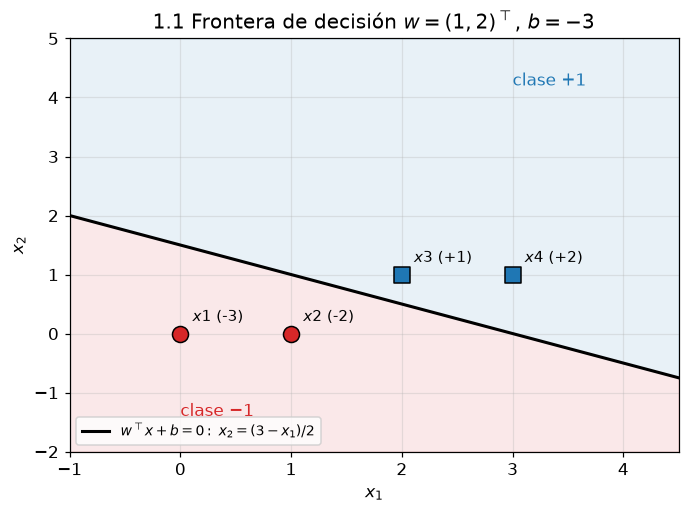

In [3]:

w1 = np.array([1.0, 2.0])
b1 = -3.0

puntos = {"x1": (0, 0), "x2": (1, 0), "x3": (2, 1), "x4": (3, 1)}
norma_w = np.linalg.norm(w1)

print(f"Frontera: {w1[0]:.0f}*x1 + {w1[1]:.0f}*x2 {b1:+.0f} = 0"
      f"  ->  x2 = {( -b1)/w1[1]:.2f} + ({-w1[0]/w1[1]:.2f})*x1")
print(f"||w|| = {norma_w:.4f}\n")
print(f"{'punto':>6} {'x':>10} {'w.x+b':>8} {'signo':>7} {'y_hat':>6} {'dist. a frontera':>17}")
for nombre, p in puntos.items():
    x = np.array(p, dtype=float)
    f = float(w1 @ x + b1)
    yhat = 1 if f > 0 else -1
    signo = "+" if f > 0 else "-"
    print(f"{nombre:>6} {str(p):>10} {f:>8.1f} {signo:>7}"
          f" {yhat:>6d} {abs(f)/norma_w:>17.4f}")

# --- Figura: recta de decisión y los cuatro puntos --------------------------
fig, ax = plt.subplots(figsize=(6.4, 4.8))
xs = np.linspace(-1.0, 4.5, 200)
ax.plot(xs, (3 - xs) / 2, color="black", lw=2, label=r"$w^\top x + b = 0:\ x_2 = (3-x_1)/2$")
ax.fill_between(xs, (3 - xs) / 2, 5.0, color="tab:blue", alpha=0.10)
ax.fill_between(xs, (3 - xs) / 2, -2.0, color="tab:red", alpha=0.10)

marcadores = {"x1": ("o", (0, 0)), "x2": ("o", (1, 0)), "x3": ("s", (2, 1)), "x4": ("s", (3, 1))}
for nombre, (marc, p) in marcadores.items():
    f = w1 @ np.array(p) + b1
    color = "tab:blue" if f > 0 else "tab:red"
    ax.scatter(*p, marker=marc, s=110, color=color, edgecolor="black", zorder=5)
    ax.annotate(f"${nombre}$ ({int(f):+d})", p, textcoords="offset points",
                xytext=(8, 8), fontsize=10)

ax.set_xlim(-1.0, 4.5)
ax.set_ylim(-2.0, 5.0)
ax.set_xlabel(r"$x_1$")
ax.set_ylabel(r"$x_2$")
ax.set_title("1.1 Frontera de decisión $w=(1,2)^\\top$, $b=-3$")
ax.text(3.0, 4.2, "clase $+1$", color="tab:blue", fontsize=11)
ax.text(0.0, -1.4, "clase $-1$", color="tab:red", fontsize=11)
ax.legend(loc="lower left", fontsize=9)
fig.savefig(FIGURAS / "fig_1_1_frontera.png", bbox_inches="tight")
plt.show()



### 1.2 Actualización del perceptrón y el margen

Definimos el margen de la observación $i$ como $m_i = y_i\,(w^\top x_i + b)$.
Con la regla $w_{\text{nuevo}} = w + \eta\,y_i x_i$ y
$b_{\text{nuevo}} = b + \eta\,y_i$, calculamos el margen después de la
actualización sobre la **misma** observación:

$$
\begin{aligned}
m_{i,\text{nuevo}}
&= y_i\left(w_{\text{nuevo}}^\top x_i + b_{\text{nuevo}}\right) \\
&= y_i\left((w + \eta\,y_i x_i)^\top x_i + b + \eta\,y_i\right) \\
&= y_i\left(w^\top x_i + b\right)
   + \eta\,y_i\,\big(y_i\,x_i^\top x_i\big)
   + \eta\,y_i^2 \\
&= m_i + \eta\,y_i^2\,\lVert x_i\rVert_2^2 + \eta\,y_i^2 .
\end{aligned}
$$

Como $y_i \in \{-1,+1\}$, se cumple $y_i^2 = 1$, de donde

$$
\boxed{\,m_{i,\text{nuevo}} = m_i + \eta\left(\lVert x_i\rVert_2^2 + 1\right)\,}
$$

con $\eta > 0$ y $\lVert x_i\rVert_2^2 + 1 > 0$.

**Qué implica.** El incremento es **estrictamente positivo** y **no depende del
valor de $m_i$**: no importa cuán mal clasificada esté la observación, el paso
la mueve siempre en la dirección correcta. Si estaba mal clasificada
($m_i \le 0$), la mera aplicación repetida del paso no basta para garantizar el
cambio de signo en una sola iteración, porque el desplazamiento necesario
depende de $\lvert m_i\rvert$; con lo que sí se cuenta es con un avance fijo
$\eta(\lVert x_i\rVert^2+1)$ hacia el lado correcto.

Dos precisiones importantes:

* El margen *geométrico* es $m_i / \lVert w\rVert$. El numerador crece, pero
  $\lVert w\rVert$ también cambia con la actualización, así que el margen
  geométrico no es monótono. Lo que el resultado garantiza es el crecimiento del
  margen sin normalizar (funcional).
* El algoritmo sólo actualiza cuando hay error ($y_i(w^\top x_i+b) \le 0$); los
  puntos ya bien clasificados conservan su margen. Es la base de la cota de
  convergencia del perceptrón: si los datos son linealmente separables, el
  número de errores está acotado por $(R/\gamma)^2$, con $R = \max_i\lVert x_i\rVert$
  y $\gamma$ el margen geométrico del separador óptimo.


In [4]:

# Verificación numérica de la identidad m_nuevo = m + eta*(||x||^2 + 1)
rng = np.random.default_rng(SEMILLA)
eta = 0.5

def actualizar(w, b, x, y, eta):
    return w + eta * y * x, b + eta * y

print(f"{'caso':>5} {'margen_i':>10} {'margen_nuevo':>13} {'margen+incr':>12} {'y_hat nuevo':>12}")
for caso in range(1, 6):
    w = rng.normal(size=2)
    b = rng.normal()
    y = rng.choice([-1.0, 1.0])
    x = rng.normal(size=2)
    # forzamos que la observación esté mal clasificada (o al menos en la frontera)
    if y * (w @ x + b) > 0:
        y = -y
    m_i = float(y * (w @ x + b))
    incremento = eta * (float(x @ x) + 1.0)
    w_n, b_n = actualizar(w, b, x, y, eta)
    m_nuevo = float(y * (w_n @ x + b_n))
    print(f"{caso:>5} {m_i:>10.4f} {m_nuevo:>13.4f} {m_i + incremento:>12.4f}"
          f" {('+' if y*(w_n @ x + b_n) > 0 else '-'):>12}")
    assert np.isclose(m_nuevo, m_i + incremento), "la identidad no se cumple"
    assert m_nuevo > m_i, "el margen no aumentó"

print("\nLa identidad se cumple en los cinco casos y el margen siempre aumenta.")


 caso   margen_i  margen_nuevo  margen+incr  y_hat nuevo
    1    -1.5102        1.7409       1.7409            +
    2    -0.4040        0.8466       0.8466            +
    3    -0.4832        0.4539       0.4539            +
    4    -0.4708        0.2781       0.2781            +
    5    -0.1660        0.5425       0.5425            +

La identidad se cumple en los cinco casos y el margen siempre aumenta.



### 1.3 Ejercicio numérico

Datos: $w = (0,0)^\top$, $b = 0$, $\eta = 0.5$, $x = (2,1)^\top$, $y = +1$.

**Paso 1 — ¿hay error?** El puntaje es $w^\top x + b = 0\cdot 2 + 0\cdot 1 + 0 = 0$.
La regla de predicción dice $\hat y = +1$ sólo si el puntaje es $> 0$; aquí vale
$0$, que **no** es mayor que cero, así que $\hat y = -1$.

Con $y = +1$ y $\hat y = -1$ la observación está **mal clasificada**
($m = y(w^\top x + b) = 0 \le 0$), por lo tanto **sí corresponde actualizar**.

**Paso 2 — actualización** con $\eta\,y = 0.5 \cdot (+1) = 0.5$:

$$
w_{\text{nuevo}} = \begin{pmatrix}0\\0\end{pmatrix} + 0.5\,(+1)\begin{pmatrix}2\\1\end{pmatrix}
= \begin{pmatrix}1\\0.5\end{pmatrix},
\qquad
b_{\text{nuevo}} = 0 + 0.5\,(+1) = 0.5 .
$$

**Paso 3 — nuevo margen**

$$
m_{\text{nuevo}} = y\left(w_{\text{nuevo}}^\top x + b_{\text{nuevo}}\right)
= (+1)\left(1\cdot 2 + 0.5\cdot 1 + 0.5\right) = 2 + 0.5 + 0.5 = 3 .
$$

**Comprobación con la fórmula de 1.2:**
$m + \eta(\lVert x\rVert_2^2 + 1) = 0 + 0.5\,(2^2 + 1^2 + 1) = 0.5\cdot 6 = 3$. ✓

El nuevo puntaje es positivo, de modo que la observación pasa a estar bien
clasificada; su margen funcional es $3$ y el geométrico
$3/\lVert w_{\text{nuevo}}\rVert = 3/\sqrt{1^2 + 0.5^2} = 3/1.1180 \approx 2.68$.


In [5]:

w = np.array([0.0, 0.0])
b = 0.0
eta = 0.5
x = np.array([2.0, 1.0])
y = 1.0

puntaje = float(w @ x + b)
yhat = 1 if puntaje > 0 else -1
m_i = y * puntaje
print(f"Puntaje w.x + b = {puntaje:.1f}  ->  y_hat = {yhat:+d}  (y real = {y:+.0f})")
print(f"Margen actual m = {m_i:.1f}  ->  {'hay error: se actualiza' if m_i <= 0 else 'sin error'}")

w_n, b_n = actualizar(w, b, x, y, eta)
m_nuevo = float(y * (w_n @ x + b_n))

print(f"\nw_nuevo = {w_n}   b_nuevo = {b_n:.1f}")
print(f"Margen nuevo = {m_nuevo:.4f}")
print(f"Formula 1.2: m + eta*(||x||^2 + 1) = {m_i + eta * (float(x @ x) + 1):.4f}")
print(f"Margen geometrico = m_nuevo/||w_nuevo|| = {m_nuevo / np.linalg.norm(w_n):.4f}")


Puntaje w.x + b = 0.0  ->  y_hat = -1  (y real = +1)
Margen actual m = 0.0  ->  hay error: se actualiza

w_nuevo = [1.  0.5]   b_nuevo = 0.5
Margen nuevo = 3.0000
Formula 1.2: m + eta*(||x||^2 + 1) = 3.0000
Margen geometrico = m_nuevo/||w_nuevo|| = 2.6833



---

## 2. Clasificación por los $k$ vecinos más cercanos (k-NN)

Observación a clasificar: $q = (1,1)$. Conjunto de entrenamiento:

| Observación | $x_1$ | $x_2$ | $x_3$ | $x_4$ | $x_5$ |
|---|---|---|---|---|---|
| $x_i$ | $(0,0)$ | $(1,0)$ | $(3,1)$ | $(0,3)$ | $(1.1,\,1.1)$ |
| Clase | A | A | B | B | B |

### 2.1 Cálculo manual

Distancia euclidiana $d(q,x_i) = \sqrt{(q_1 - x_{i,1})^2 + (q_2 - x_{i,2})^2}$:

$$
\begin{aligned}
d(q,x_1) &= \sqrt{(1-0)^2 + (1-0)^2} = \sqrt{2} \approx 1.4142,\\
d(q,x_2) &= \sqrt{(1-1)^2 + (1-0)^2} = \sqrt{1} = 1.0000,\\
d(q,x_3) &= \sqrt{(1-3)^2 + (1-1)^2} = \sqrt{4} = 2.0000,\\
d(q,x_4) &= \sqrt{(1-0)^2 + (1-3)^2} = \sqrt{5} \approx 2.2361,\\
d(q,x_5) &= \sqrt{(1-1.1)^2 + (1-1.1)^2} = \sqrt{0.02} \approx 0.1414 .
\end{aligned}
$$

**Orden de cercanía a lejanía** (todos los valores son distintos, así que el
orden es único y no hay empates que romper):

| Puesto | Observación | Distancia | Clase |
|---|---|---|---|
| 1 | $x_5 = (1.1,1.1)$ | $0.1414$ | B |
| 2 | $x_2 = (1,0)$ | $1.0000$ | A |
| 3 | $x_1 = (0,0)$ | $1.4142$ | A |
| 4 | $x_3 = (3,1)$ | $2.0000$ | B |
| 5 | $x_4 = (0,3)$ | $2.2361$ | B |

**Clasificación de $q$ por votación mayoritaria**

* $k=1$: vecino $\{x_5\}$ → votos A: 0, B: 1 → $\hat y = \mathbf{B}$.
* $k=3$: vecinos $\{x_5, x_2, x_1\}$ → votos A: 2, B: 1 → $\hat y = \mathbf{A}$.
* $k=5$: vecinos todos → votos A: 2, B: 3 → $\hat y = \mathbf{B}$.

**Por qué $k$ puede cambiar la predicción.** El vecino más cercano $x_5$ está a
distancia $0.14$ de $q$ y es de clase B; es un punto "fronterizo" que está casi
sobre $q$. Al pasar a $k=3$ entran $x_2$ y $x_1$, ambos A, que son la mayoría y
anulan el voto de $x_5$. Al llegar a $k=5$ se incorporan $x_3$ y $x_4$, ambos B,
y ahora la mayoría B (3 contra 2) depende de puntos que están a más de 2
unidades de $q$, es decir, de la tendencia global del conjunto y no de la
localidad de $q$. En general $k$ controla el **compromiso sesgo–varianza**:
$k$ pequeño usa sólo la vecindad inmediata (fronteras muy irregulares, sensible
al ruido); $k$ grande promedia sobre una región amplia (fronteras suaves, pero
puede diluir la estructura local y arrastrar la clase mayoritaria). Con $N=5$ y
sin empates, el conjunto de vecinos crece en pasos impares y la predicción puede
"oscilar" como aquí (B → A → B).


Distancias d(q, x_i) y orden de cercanía
 puesto   obs            x_i  distancia  clase
      1    x5     (1.1, 1.1)     0.1414      B
      2    x2     (1.0, 0.0)     1.0000      A
      3    x1     (0.0, 0.0)     1.4142      A
      4    x3     (3.0, 1.0)     2.0000      B
      5    x4     (0.0, 3.0)     2.2361      B

Votación mayoritaria para q = (1, 1)
  k=1: vecinos [x5=B] | votos {'B': 1} -> y_hat = B
  k=3: vecinos [x5=B, x2=A, x1=A] | votos {'B': 1, 'A': 2} -> y_hat = A
  k=5: vecinos [x5=B, x2=A, x1=A, x3=B, x4=B] | votos {'B': 3, 'A': 2} -> y_hat = B


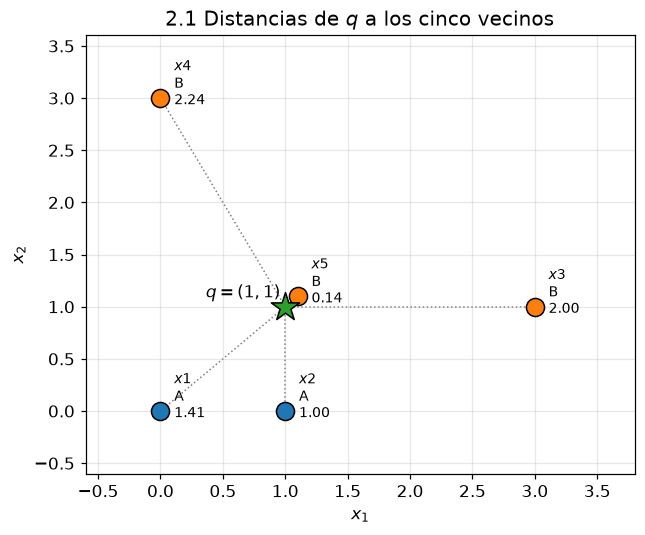

In [6]:

q = np.array([1.0, 1.0])
X = np.array([[0.0, 0.0], [1.0, 0.0], [3.0, 1.0], [0.0, 3.0], [1.1, 1.1]])
clases = np.array(["A", "A", "B", "B", "B"])
nombres = np.array(["x1", "x2", "x3", "x4", "x5"])

distancias = np.linalg.norm(X - q, axis=1)
orden = np.argsort(distancias, kind="stable")

print("Distancias d(q, x_i) y orden de cercanía")
print(f"{'puesto':>7} {'obs':>5} {'x_i':>14} {'distancia':>10} {'clase':>6}")
for puesto, i in enumerate(orden, start=1):
    xi_txt = f"({X[i, 0]:.1f}, {X[i, 1]:.1f})"
    print(f"{puesto:>7} {nombres[i]:>5} {xi_txt:>14} {distancias[i]:>10.4f} {clases[i]:>6}")


def knn_manual(q, X, clases, k):
    # k-NN con votación mayoritaria implementada a mano (sin sklearn).
    d = np.linalg.norm(X - q, axis=1)
    idx = np.argsort(d, kind="stable")[:k]
    votos = {}
    for c in clases[idx]:
        votos[str(c)] = votos.get(str(c), 0) + 1
    ordenados = sorted(votos.items(), key=lambda kv: (-kv[1], kv[0]))
    empate = len(ordenados) > 1 and ordenados[0][1] == ordenados[1][1]
    return ordenados[0][0], votos, idx, empate


print("\nVotación mayoritaria para q = (1, 1)")
for k in (1, 3, 5):
    pred, votos, idx, empate = knn_manual(q, X, clases, k)
    detalle = ", ".join(f"{nombres[i]}={clases[i]}" for i in idx)
    print(f"  k={k}: vecinos [{detalle}] | votos {votos} "
          f"-> y_hat = {pred}{' (EMPATE)' if empate else ''}")

# Figura ilustrativa: q, los cinco puntos y sus distancias
fig, ax = plt.subplots(figsize=(6.0, 5.0))
for i, (xi, c) in enumerate(zip(X, clases)):
    color = "tab:blue" if c == "A" else "tab:orange"
    ax.scatter(*xi, s=140, color=color, edgecolor="black", zorder=5)
    ax.annotate(f"${nombres[i]}$\n{c}\n{distancias[i]:.2f}", xi, textcoords="offset points",
                xytext=(9, -4), fontsize=9)
    ax.plot([q[0], xi[0]], [q[1], xi[1]], ls=":", lw=1, color="gray", zorder=1)
ax.scatter(*q, marker="*", s=380, color="tab:green", edgecolor="black", zorder=6)
ax.annotate("$q=(1,1)$", q, textcoords="offset points", xytext=(-52, 6), fontsize=11)
ax.set_xlabel(r"$x_1$")
ax.set_ylabel(r"$x_2$")
ax.set_title("2.1 Distancias de $q$ a los cinco vecinos")
ax.set_xlim(-0.6, 3.8)
ax.set_ylim(-0.6, 3.6)
fig.savefig(FIGURAS / "fig_2_1_distancias.png", bbox_inches="tight")
plt.show()



### 2.2 Implementación con `make_moons`

Protocolo: $N = 300$, `noise=0.20`, `random_state=42`; partición 70 % entrenamiento
/ 30 % prueba **estratificada** (`stratify=y`, `random_state=42`); `KNeighborsClassifier`
con $k \in \{1, 5, 15\}$ (distancia euclidiana por defecto y votación uniforme).
Se reporta la exactitud en entrenamiento y en prueba.


Forma del conjunto: (300, 2) | clases: [150 150]
Entrenamiento: 210 obs (clases [105 105])
Prueba:        90 obs (clases [45 45])

Exactitud por k (make_moons, noise=0.20, N=300)
  k  exactitud train  exactitud test
  1           1.0000          0.9333
  5           0.9571          0.9556
 15           0.9571          0.9333


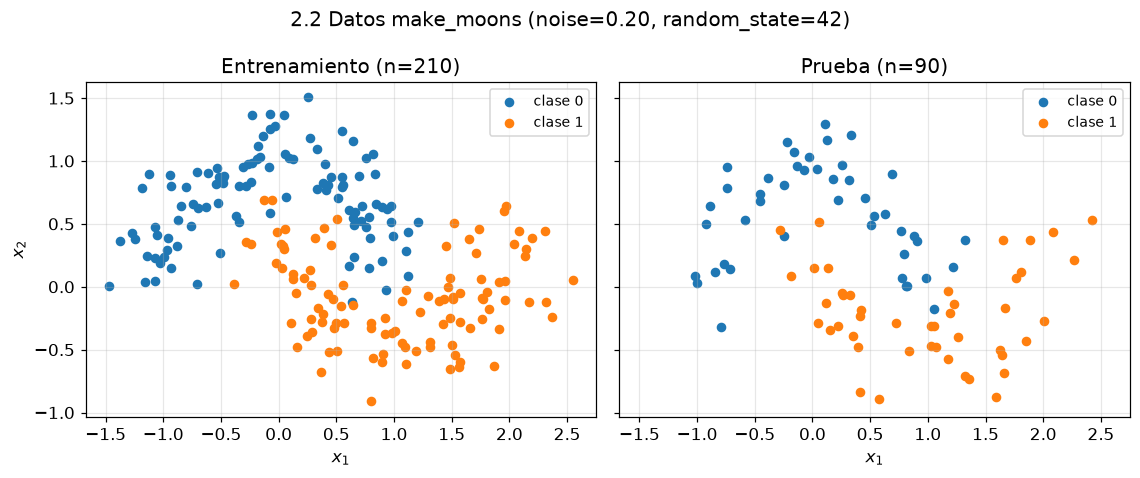

In [7]:

X_moons, y_moons = make_moons(n_samples=300, noise=0.20, random_state=SEMILLA)
print("Forma del conjunto:", X_moons.shape, "| clases:", np.bincount(y_moons))

X_train, X_test, y_train, y_test = train_test_split(
    X_moons, y_moons, test_size=0.30, stratify=y_moons, random_state=SEMILLA)
print(f"Entrenamiento: {len(y_train)} obs (clases {np.bincount(y_train)})")
print(f"Prueba:        {len(y_test)} obs (clases {np.bincount(y_test)})")

resultados = {}
print("\nExactitud por k (make_moons, noise=0.20, N=300)")
print(f"{'k':>3} {'exactitud train':>16} {'exactitud test':>15}")
for k in (1, 5, 15):
    modelo = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    acc_tr = accuracy_score(y_train, modelo.predict(X_train))
    acc_te = accuracy_score(y_test, modelo.predict(X_test))
    resultados[k] = {"acc_train": acc_tr, "acc_test": acc_te}
    print(f"{k:>3} {acc_tr:>16.4f} {acc_te:>15.4f}")

# --- Figura: datos de entrenamiento y prueba -------------------------------
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4), sharex=True, sharey=True)
for ax, (Xt, yt, titulo) in zip(axes, [
        (X_train, y_train, f"Entrenamiento (n={len(y_train)})"),
        (X_test, y_test, f"Prueba (n={len(y_test)})")]):
    ax.scatter(Xt[yt == 0, 0], Xt[yt == 0, 1], s=28, color="tab:blue", label="clase 0")
    ax.scatter(Xt[yt == 1, 0], Xt[yt == 1, 1], s=28, color="tab:orange", label="clase 1")
    ax.set_title(titulo)
    ax.set_xlabel(r"$x_1$")
    ax.legend(fontsize=9)
axes[0].set_ylabel(r"$x_2$")
fig.suptitle("2.2 Datos make_moons (noise=0.20, random_state=42)")
fig.savefig(FIGURAS / "fig_2_2_datos.png", bbox_inches="tight")
plt.show()


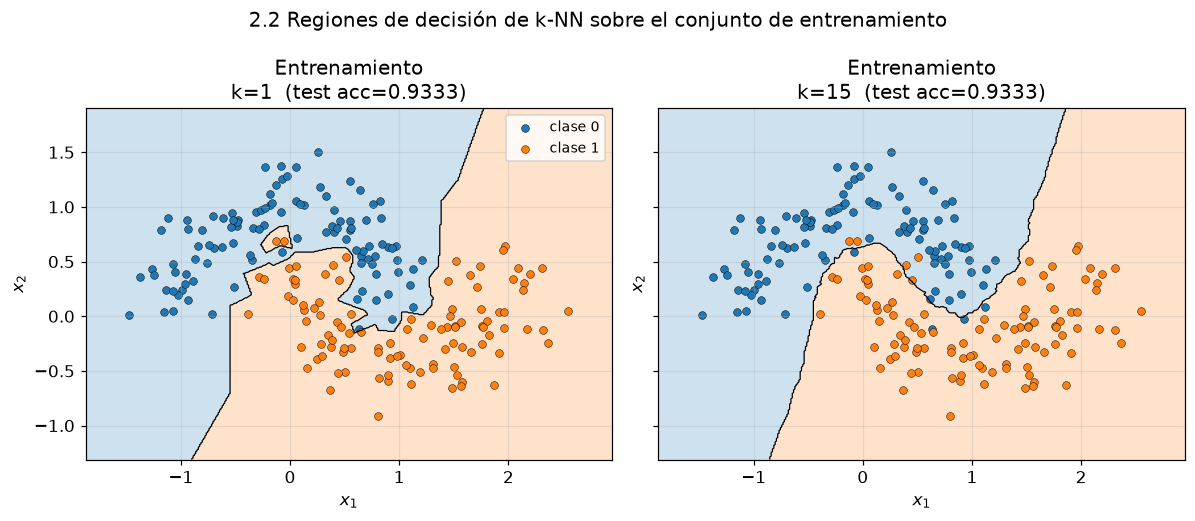

In [8]:

# --- Regiones de decisión para k = 1 y k = 15 ------------------------------
def dibujar_frontera(ax, modelo, X, y, k, titulo):
    x_min, x_max = X[:, 0].min() - 0.4, X[:, 0].max() + 0.4
    y_min, y_max = X[:, 1].min() - 0.4, X[:, 1].max() + 0.4
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400), np.linspace(y_min, y_max, 400))
    Z = modelo.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.22, colors=["tab:blue", "tab:orange"], levels=[-0.5, 0.5, 1.5])
    ax.contour(xx, yy, Z, colors="k", linewidths=0.8, levels=[0.5])
    ax.scatter(X[y == 0, 0], X[y == 0, 1], s=26, color="tab:blue", edgecolor="k", lw=0.3, label="clase 0")
    ax.scatter(X[y == 1, 0], X[y == 1, 1], s=26, color="tab:orange", edgecolor="k", lw=0.3, label="clase 1")
    ax.set_title(f"{titulo}\nk={k}  (test acc={resultados[k]['acc_test']:.4f})")
    ax.set_xlabel(r"$x_1$")
    ax.set_ylabel(r"$x_2$")


fig, axes = plt.subplots(1, 2, figsize=(11.0, 4.8), sharex=True, sharey=True)
for ax, k in zip(axes, (1, 15)):
    modelo = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    dibujar_frontera(ax, modelo, X_train, y_train, k, "Entrenamiento")
axes[0].legend(fontsize=9, loc="upper right")
fig.suptitle("2.2 Regiones de decisión de k-NN sobre el conjunto de entrenamiento")
fig.savefig(FIGURAS / "fig_2_2_regiones.png", bbox_inches="tight")
plt.show()



### 2.3 Interpretación

**Qué ocurre con $k$ muy pequeño.** Con $k=1$ cada observación se clasifica según
su vecino inmediato: la exactitud de entrenamiento es $1.0000$ por construcción
(cada punto es su propio vecino más cercano), la frontera es muy irregular y se
"amolda" al ruido. Es un modelo de **varianza alta**: pequeñas perturbaciones en
los datos cambian mucho la frontera y puede haber islas y bolsillos de la otra
clase dentro de cada luna.

**Qué ocurre con $k$ muy grande.** Al promediar muchos vecinos la frontera se
suaviza y se vuelve más estable frente al ruido, pero el sesgo aumenta: si $k$
llega a ser comparable con el tamaño de la muestra, la vecindad cubre casi todo
el espacio y la predicción tiende a la clase mayoritaria, perdiendo la estructura
local (las dos lunas). Con $k=15$ ya se observa una frontera más limpia y menos
accidentada.

**Cuál generalizó mejor.** En esta corrida ($N=300$, `noise=0.20`, semilla 42,
210 observaciones de entrenamiento y 90 de prueba) las exactitudes de prueba son

$$
k=1:\ 0.9333, \qquad k=5:\ 0.9556, \qquad k=15:\ 0.9333,
$$

de modo que el mejor de los tres es $k=5$ (0.9556, es decir $86/90$ aciertos).
La justificación no es "el de mayor exactitud de entrenamiento" —ese siempre
favorece a $k=1$, que memoriza con $1.0000$— sino el comportamiento sobre datos
no vistos: $k=1$ sufre el ruido de los puntos de la frontera de las lunas, y
$k=15$ suaviza tanto la frontera que pierde algunos puntos de las "colas";
$k=5$ conserva la forma local y descarta el ruido puntual. Las diferencias son
pequeñas (una o dos observaciones de prueba), lo que indica que con `noise=0.20`
el problema es relativamente sencillo para k-NN.

**Por qué el mejor $k$ debe elegirse con validación y no con prueba.** La
exactitud de prueba estima el desempeño de un modelo **ya elegido** sobre datos
que el procedimiento no utilizó. Si se prueban muchos $k$ y se escoge el que
maximiza la exactitud de prueba, ese conjunto deja de ser una muestra
independiente: el número reportado queda **sesgado de manera optimista** y
sobreestima el desempeño real (fuga de información / selección sobre el
conjunto de evaluación). La práctica correcta es seleccionar $k$ dentro del
conjunto de entrenamiento con **validación cruzada estratificada** (o un
conjunto de validación separado) y reservar el conjunto de prueba, sin tocarlo,
para un único reporte final. La celda siguiente muestra esa selección por
validación cruzada de 5 pliegues sobre el entrenamiento y, sólo como
comprobación, la exactitud de prueba del $k$ seleccionado.


Validación cruzada (5 pliegues) sobre el entrenamiento
  k  acc CV media  desv. est.
  1        0.9381      0.0243
  3        0.9333      0.0233
  5        0.9524      0.0213
  7        0.9524      0.0261
  9        0.9571      0.0278
 11        0.9619      0.0323  <-- mejor
 13        0.9571      0.0278
 15        0.9571      0.0278
 17        0.9524      0.0261
 19        0.9476      0.0233
 21        0.9524      0.0261
 23        0.9524      0.0261
 25        0.9571      0.0316
 27        0.9571      0.0316
 29        0.9524      0.0301
 31        0.9476      0.0316
 33        0.9429      0.0356
 35        0.9381      0.0356
 37        0.9381      0.0356
 39        0.9333      0.0278

k elegido por CV = 11 (acc CV = 0.9619); su exactitud de prueba, reportada una sola vez = 0.9667


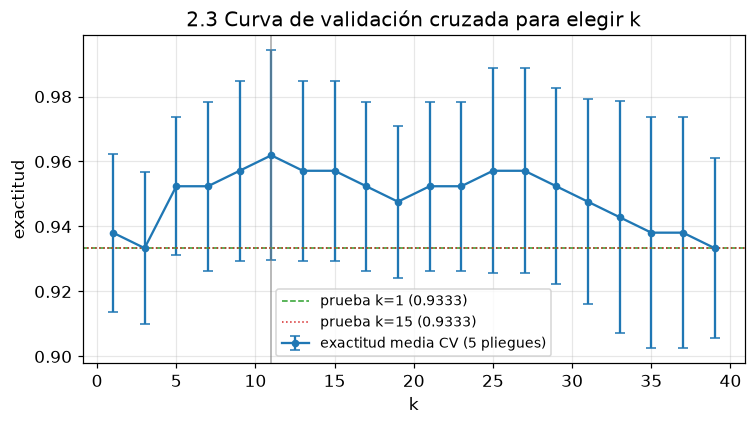

In [9]:

# Selección de k SOLO con el conjunto de entrenamiento (validación cruzada 5-fold)
ks = list(range(1, 41, 2))
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
medias, desv = [], []
for k in ks:
    scores = cross_val_score(KNeighborsClassifier(n_neighbors=k), X_train, y_train,
                             cv=cv, scoring="accuracy")
    medias.append(scores.mean())
    desv.append(scores.std())

medias, desv = np.array(medias), np.array(desv)
k_cv = ks[int(np.argmax(medias))]
acc_test_cv = accuracy_score(y_test, KNeighborsClassifier(n_neighbors=k_cv)
                            .fit(X_train, y_train).predict(X_test))

print("Validación cruzada (5 pliegues) sobre el entrenamiento")
print(f"{'k':>3} {'acc CV media':>13} {'desv. est.':>11}")
for k, m, s in zip(ks, medias, desv):
    marca = "  <-- mejor" if k == k_cv else ""
    print(f"{k:>3} {m:>13.4f} {s:>11.4f}{marca}")
print(f"\nk elegido por CV = {k_cv} (acc CV = {medias[ks.index(k_cv)]:.4f});"
      f" su exactitud de prueba, reportada una sola vez = {acc_test_cv:.4f}")

fig, ax = plt.subplots(figsize=(7.0, 4.0))
ax.errorbar(ks, medias, yerr=desv, marker="o", ms=4, capsize=3, color="tab:blue",
            label="exactitud media CV (5 pliegues)")
ax.axhline(resultados[1]["acc_test"], color="tab:green", ls="--", lw=1,
           label=f"prueba k=1 ({resultados[1]['acc_test']:.4f})")
ax.axhline(resultados[15]["acc_test"], color="tab:red", ls=":", lw=1,
           label=f"prueba k=15 ({resultados[15]['acc_test']:.4f})")
ax.axvline(k_cv, color="gray", lw=1, alpha=0.7)
ax.set_xlabel("k")
ax.set_ylabel("exactitud")
ax.set_title("2.3 Curva de validación cruzada para elegir k")
ax.legend(fontsize=9)
fig.savefig(FIGURAS / "fig_2_3_cv.png", bbox_inches="tight")
plt.show()



---

## 3. Evaluación de un clasificador binario

Etiquetas reales y predichas, con la clase 1 como **positiva**:

$$
y = [0,0,0,0,1,1,1,1,1,1], \qquad
\hat y = [0,1,0,0,1,0,1,1,0,1].
$$

### 3.1 Matriz de confusión (filas = clase real, columnas = clase predicha)

Recorriendo las diez posiciones:

| # | $y$ | $\hat y$ | Resultado |
|---|---|---|---|
| 1 | 0 | 0 | $TN$ |
| 2 | 0 | 1 | $FP$ |
| 3 | 0 | 0 | $TN$ |
| 4 | 0 | 0 | $TN$ |
| 5 | 1 | 1 | $TP$ |
| 6 | 1 | 0 | $FN$ |
| 7 | 1 | 1 | $TP$ |
| 8 | 1 | 1 | $TP$ |
| 9 | 1 | 0 | $FN$ |
| 10 | 1 | 1 | $TP$ |

$$
\text{Matriz de confusión} =
\begin{array}{c|cc}
 & \hat y = 0 & \hat y = 1 \\\hline
y = 0 & TN = 3 & FP = 1 \\
y = 1 & FN = 2 & TP = 4
\end{array}
$$

Por lo tanto $TP = 4$, $TN = 3$, $FP = 1$, $FN = 2$. Comprobación:
$3 + 1 + 2 + 4 = 10$ observaciones, y $TP + FN = 6$ positivos reales,
$TN + FP = 4$ negativos reales.

### 3.2 Métricas

$$
\text{Accuracy} = \frac{TP+TN}{TP+TN+FP+FN} = \frac{4+3}{10} = \frac{7}{10} = 0.70\;(70\,\%)
$$

$$
\text{Precision} = \frac{TP}{TP+FP} = \frac{4}{4+1} = 0.80\;(80\,\%)
$$

$$
\text{Recall} = \frac{TP}{TP+FN} = \frac{4}{4+2} = \frac{2}{3} \approx 0.6667\;(66.67\,\%)
$$

$$
F_1 = \frac{2\,\text{Precision}\,\text{Recall}}{\text{Precision}+\text{Recall}}
= \frac{2\cdot 0.8 \cdot (2/3)}{0.8 + 2/3}
= \frac{16/15}{22/15} = \frac{8}{11} \approx 0.7273\;(72.73\,\%)
$$

**Qué evalúa cada medida**

* **Accuracy**: proporción de aciertos sobre el total (positivos y negativos). Es
  una medida global y simétrica; útil cuando ambas clases importan igual.
* **Precision** (valor predictivo positivo): de todo lo que el modelo marcó como
  positivo, qué fracción era realmente positiva. Mide el **costo de las falsas
  alarmas** ($FP$); importa cuando un positivo predicho dispara una acción
  costosa (p. ej. una alerta, un tratamiento invasivo, un bloqueo de cuenta).
* **Recall** (sensibilidad, exhaustividad): de todos los positivos reales, qué
  fracción fue detectada. Mide el **costo de los falsos negativos** ($FN$);
  importa cuando no detectar un positivo es grave (enfermedad, fraude, falla).
* **$F_1$**: media armónica de precision y recall. Castiga el desequilibrio entre
  ambas: un modelo con precision 1.0 y recall 0.1 tiene $F_1 \approx 0.18$. Es
  adecuada cuando hay desbalance de clases y ambos tipos de error importan.


Matriz de confusión manual (filas = real, columnas = predicho)
[[3 1]
 [2 4]]
TP=4  TN=3  FP=1  FN=2  | total=10

Manual    -> accuracy=0.7000  precision=0.8000  recall=0.6667  f1=0.7273
Fracciones -> accuracy=7/10  precision=4/5  recall=2/3  f1=8/11=0.7273

Verificación con scikit-learn
confusion_matrix =
 [[3 1]
 [2 4]]
accuracy_score   = 0.7000
precision_score  = 0.8000
recall_score     = 0.6667
f1_score         = 0.7273

Coincidencia exacta entre el cálculo manual y scikit-learn. OK


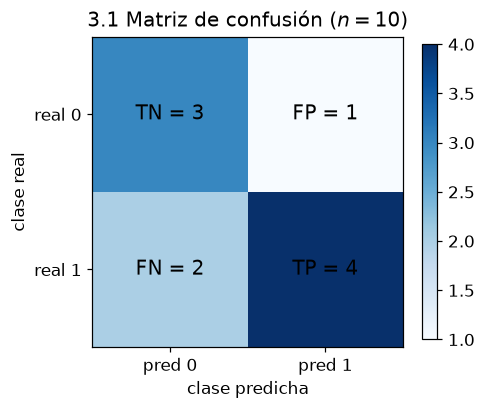

In [10]:

y_real = np.array([0, 0, 0, 0, 1, 1, 1, 1, 1, 1])
y_pred = np.array([0, 1, 0, 0, 1, 0, 1, 1, 0, 1])

# --- Matriz de confusión calculada a mano (sin sklearn) --------------------
TP = int(np.sum((y_real == 1) & (y_pred == 1)))
TN = int(np.sum((y_real == 0) & (y_pred == 0)))
FP = int(np.sum((y_real == 0) & (y_pred == 1)))
FN = int(np.sum((y_real == 1) & (y_pred == 0)))

matriz_manual = np.array([[TN, FP], [FN, TP]])
print("Matriz de confusión manual (filas = real, columnas = predicho)")
print(matriz_manual)
print(f"TP={TP}  TN={TN}  FP={FP}  FN={FN}  | total={TP+TN+FP+FN}")

# --- Métricas manuales ------------------------------------------------------
acc_manual = (TP + TN) / (TP + TN + FP + FN)
prec_manual = TP / (TP + FP)
rec_manual = TP / (TP + FN)
f1_manual = 2 * prec_manual * rec_manual / (prec_manual + rec_manual)

print(f"\nManual    -> accuracy={acc_manual:.4f}  precision={prec_manual:.4f}"
      f"  recall={rec_manual:.4f}  f1={f1_manual:.4f}")
print(f"Fracciones -> accuracy=7/10  precision=4/5  recall=2/3  f1=8/11={8/11:.4f}")

# --- Verificación con scikit-learn -----------------------------------------
matriz_sk = confusion_matrix(y_real, y_pred, labels=[0, 1])
acc_sk = accuracy_score(y_real, y_pred)
prec_sk = precision_score(y_real, y_pred, pos_label=1)
rec_sk = recall_score(y_real, y_pred, pos_label=1)
f1_sk = f1_score(y_real, y_pred, pos_label=1)

print("\nVerificación con scikit-learn")
print("confusion_matrix =\n", matriz_sk)
print(f"accuracy_score   = {acc_sk:.4f}")
print(f"precision_score  = {prec_sk:.4f}")
print(f"recall_score     = {rec_sk:.4f}")
print(f"f1_score         = {f1_sk:.4f}")

assert np.array_equal(matriz_manual, matriz_sk), "la matriz no coincide"
assert np.isclose(acc_manual, acc_sk) and np.isclose(prec_manual, prec_sk)
assert np.isclose(rec_manual, rec_sk) and np.isclose(f1_manual, f1_sk)
print("\nCoincidencia exacta entre el cálculo manual y scikit-learn. OK")

# --- Figura: matriz de confusión ------------------------------------------
fig, ax = plt.subplots(figsize=(4.6, 4.0))
im = ax.imshow(matriz_sk, cmap="Blues")
etiquetas = [["TN", "FP"], ["FN", "TP"]]
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{etiquetas[i][j]} = {matriz_sk[i, j]}", ha="center", va="center",
                fontsize=13, color="white" if matriz_sk[i, j] > 4 else "black")
ax.set_xticks([0, 1], ["pred 0", "pred 1"])
ax.set_yticks([0, 1], ["real 0", "real 1"])
ax.set_xlabel("clase predicha")
ax.set_ylabel("clase real")
ax.set_title("3.1 Matriz de confusión ($n=10$)")
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8)
fig.savefig(FIGURAS / "fig_3_1_matriz.png", bbox_inches="tight")
plt.show()



### 3.3 Verificación y análisis

**Dos situaciones en las que la exactitud por sí sola engaña**

1. **Clases desbalanceadas.** Si el 95 % de los casos son negativos, un
   clasificador trivial que siempre responde "negativo" obtiene accuracy $= 0.95$
   con recall $= 0$ para la clase positiva: nunca detecta un solo positivo. La
   exactitud es alta y el modelo es inútil para el objetivo. (Se ilustra en la
   celda siguiente con `DummyClassifier`: accuracy $0.95$, pero precision, recall
   y $F_1$ iguales a $0$ para la clase 1.)
2. **Costos asimétricos de los errores.** Un $FP$ y un $FN$ rara vez cuestan lo
   mismo. En tamizaje médico (o detección de fraude) un $FN$ puede ser un daño
   grave y un $FP$ sólo una verificación adicional; dos modelos con la misma
   exactitud pueden diferir mucho en recall/precision, y la exactitud no
   distingue cuál de los dos errores se está cometiendo. Un caso extremo: con
   accuracy $0.70$ el modelo del punto 3 deja pasar 2 de 6 positivos
   (recall $= 66.7\%$), información que la exactitud, por sí sola, oculta.

(Casos adicionales, por si se requieren: conjuntos muy pequeños donde una sola
observación mueve varios puntos porcentuales, y problemas con más de dos clases
donde la exactitud global mezcla desempeños muy distintos por clase; en ambos la
matriz de confusión y las métricas por clase son imprescindibles.)


In [11]:

# Ilustración de la situación 1: accuracy alta con un modelo inútil
y_imb = np.array([0] * 95 + [1] * 5)
X_imb = np.zeros((len(y_imb), 1))
dummy = DummyClassifier(strategy="most_frequent").fit(X_imb, y_imb)
y_imb_pred = dummy.predict(X_imb)

print("Conjunto desbalanceado: 95 negativos y 5 positivos, modelo 'siempre 0'")
print(f"accuracy  = {accuracy_score(y_imb, y_imb_pred):.4f}   <- parece excelente")
print(f"precision = {precision_score(y_imb, y_imb_pred, zero_division=0):.4f}   <- nunca acierta un positivo")
print(f"recall    = {recall_score(y_imb, y_imb_pred, zero_division=0):.4f}")
print(f"f1        = {f1_score(y_imb, y_imb_pred, zero_division=0):.4f}")

# --- Resumen numérico exportado para el informe ----------------------------
resumen = {
    "semilla": SEMILLA,
    "punto_1": {
        "w": [1.0, 2.0], "b": -3.0,
        "frontera": "x1 + 2*x2 - 3 = 0  (x2 = 1.5 - 0.5*x1)",
        "puntos": {n: {"x": list(p), "f": float(w1 @ np.array(p) + b1),
                       "yhat": int(1 if w1 @ np.array(p) + b1 > 0 else -1)}
                   for n, p in puntos.items()},
        "numerico": {"w_nuevo": [float(v) for v in w_n], "b_nuevo": float(b_n),
                     "margen_nuevo": m_nuevo},
    },
    "punto_2": {
        "q": [1.0, 1.0],
        "distancias": {nombres[i]: float(distancias[i]) for i in orden},
        "orden": [str(nombres[i]) for i in orden],
        "knn_manual": {str(k): knn_manual(q, X, clases, k)[0] for k in (1, 3, 5)},
        "acc": {str(k): v for k, v in resultados.items()},
        "n_train": int(len(y_train)), "n_test": int(len(y_test)),
        "clases_train": [int(c) for c in np.bincount(y_train)],
        "clases_test": [int(c) for c in np.bincount(y_test)],
        "k_cv": int(k_cv), "acc_cv_mejor": float(medias[ks.index(k_cv)]),
        "acc_test_k_cv": float(acc_test_cv),
    },
    "punto_3": {
        "TP": TP, "TN": TN, "FP": FP, "FN": FN,
        "matriz": matriz_sk.tolist(),
        "accuracy": float(acc_sk), "precision": float(prec_sk),
        "recall": float(rec_sk), "f1": float(f1_sk),
        "dummy_accuracy": float(accuracy_score(y_imb, y_imb_pred)),
    },
}
(RAIZ / "resultados.json").write_text(json.dumps(resumen, indent=2, ensure_ascii=False),
                                      encoding="utf-8")
print("\nResumen numérico guardado en resultados.json")


Conjunto desbalanceado: 95 negativos y 5 positivos, modelo 'siempre 0'
accuracy  = 0.9500   <- parece excelente
precision = 0.0000   <- nunca acierta un positivo
recall    = 0.0000
f1        = 0.0000

Resumen numérico guardado en resultados.json



---

## Conclusiones

1. **Frontera lineal.** El signo de $w^\top x + b$ decide la clase y el vector $w$
   es normal a la recta; con $w=(1,2)^\top$, $b=-3$ la recta $x_2 = 1.5 - 0.5x_1$
   separa $\{x_1, x_2\}$ (clase $-1$) de $\{x_3, x_4\}$ (clase $+1$).
2. **Perceptrón.** La actualización sobre una observación mal clasificada
   incrementa su margen funcional en $\eta(\lVert x_i\rVert^2+1)>0$, de forma
   independiente del error previo; el margen geométrico no es necesariamente
   monótono porque $\lVert w\rVert$ también cambia.
3. **k-NN.** El orden de cercanía a $q=(1,1)$ es $x_5, x_2, x_1, x_3, x_4$, y la
   predicción pasa de **B** ($k=1$) a **A** ($k=3$) y de nuevo a **B** ($k=5$):
   $k$ controla el compromiso sesgo–varianza. Sobre `make_moons` ($N=300$,
   `noise=0.20`), las exactitudes de prueba son $0.9333$ ($k=1$), $0.9556$
   ($k=5$) y $0.9333$ ($k=15$): $k=1$ memoriza el entrenamiento
   (accuracy $1.0000$) con frontera irregular, $k=15$ produce una frontera más
   suave y $k=5$ generaliza mejor. La elección formal de $k$ se hace por
   validación cruzada de 5 pliegues sobre el entrenamiento, que aquí selecciona
   $k=11$ (accuracy CV $0.9619$) y reporta una única vez $0.9667$ sobre la
   prueba; nunca se elige $k$ mirando el conjunto de prueba.
4. **Evaluación.** Para el ejemplo del punto 3, $TP=4$, $TN=3$, $FP=1$, $FN=2$, con
   accuracy $0.70$, precision $0.80$, recall $0.6667$ y $F_1 = 8/11 \approx 0.7273$,
   verificados con `scikit-learn`. La exactitud sola es engañosa con clases
   desbalanceadas o con costos asimétricos de los errores; precision, recall,
   $F_1$ y la matriz de confusión son necesarias para interpretar el desempeño.

**Reproducibilidad.** Todas las semillas están fijadas (`np.random.seed(42)`,
`random_state=42` en `make_moons`, `train_test_split`, `StratifiedKFold`); el
cuaderno genera las figuras en `figuras/` y el resumen numérico en
`resultados.json`.
